# Strip Plot (Jittered Dots)

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

Plots every observation as a dot along a value axis, with random sideways jitter to reduce overlap. Nothing is summarised away, so sample size, clusters and outliers stay visible.

## When to use

- Show small to medium samples (under ~300 per group) where every point matters
- Expose the raw data behind a summary statistic
- Overlay on box or violin plots

## Avoid when

- Samples are large (dots merge into a blob)

## Alternatives

- Beeswarm plot
- Box plot with points
- Raincloud plot

## Design tips

- Keep the jitter narrower than the gap between groups so lanes stay separate
- Use semi-transparent dots with a light edge so overlaps stay visible
- Draw the group mean or median as a short bar on top of the dots

## Example

Sales uplift (%) per store in a three-arm promotion test, 40 stores per arm, with group means (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(19)
arms = {"No promotion": (1, 4), "10% discount": (7, 5), "Buy 2 get 1": (11, 6)}
df = pd.concat([pd.DataFrame({"arm": a, "uplift_pct": rng.normal(m, s, 40)})
                for a, (m, s) in arms.items()], ignore_index=True)
df.groupby("arm")["uplift_pct"].agg(["mean", "std", "count"]).round(1)

,mean,std,count
arm,,,
10% discount,8.4,5.1,40
Buy 2 get 1,10.6,6.9,40
No promotion,0.1,3.4,40


### Plot

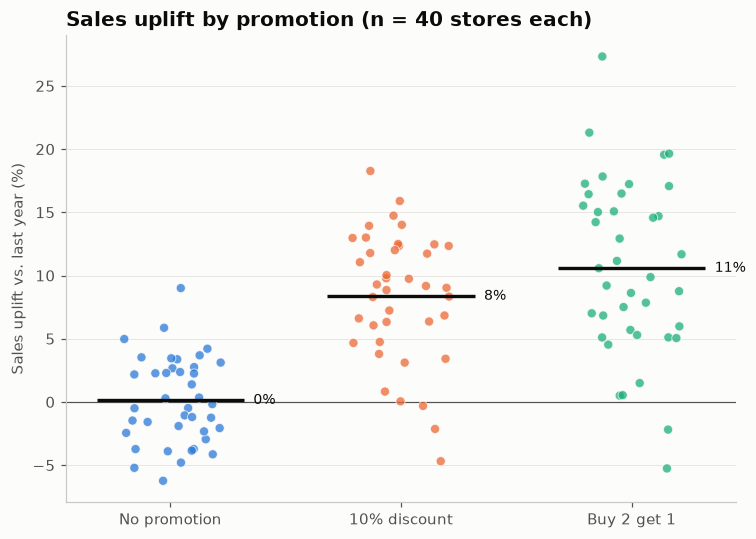

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(7, 5))
sns.stripplot(data=df, x="arm", y="uplift_pct", hue="arm", palette=PALETTE[:3], legend=False,
              jitter=0.22, size=6, alpha=0.75, edgecolor="#fcfcfb", linewidth=0.6, ax=ax)
means = df.groupby("arm", sort=False)["uplift_pct"].mean()
for i, m in enumerate(means):
    ax.hlines(m, i - 0.32, i + 0.32, color="#0b0b0b", linewidth=2.2, zorder=4)
    ax.text(i + 0.36, m, f"{m:.0f}%", va="center", fontsize=9)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.set_xlabel(None)
ax.set_ylabel("Sales uplift vs. last year (%)")
ax.set_title("Sales uplift by promotion (n = 40 stores each)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

## How to read it

Each dot is one store and the black bar is the arm's mean. Both promotions lift sales on average (8% and 11% vs. 0% with no promotion), but stores vary widely and a few promoted stores still fell, so the arms overlap more than the means suggest.

---
Standalone script: [`strip_jitter.py`](strip_jitter.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)